# 🛍️ Customer Shopping Behavior Analysis

**Author:** Ankit Kumar | [github.com/hrts51](https://github.com/hrts51)  
**End-to-end data analytics workflow:** Data Cleaning → EDA → Visualizations → RFM Segmentation → Churn Prediction → SQL Load

**Dataset:** 3,900 customer transactions | 18 features  
**Tools:** Python (pandas, seaborn, matplotlib, scikit-learn), SQL, Power BI

---
## Table of Contents
1. [Data Import & Exploration](#1-data-import--exploration)
2. [Data Cleaning](#2-data-cleaning)
3. [Feature Engineering](#3-feature-engineering)
4. [Exploratory Data Analysis (EDA)](#4-exploratory-data-analysis)
5. [RFM Customer Segmentation](#5-rfm-customer-segmentation)
6. [Churn Prediction Model](#6-churn-prediction-model)
7. [Load Data into SQL Database](#7-load-data-into-sql-database)

---
## 1. Data Import & Exploration

In [1]:
# ── Standard imports ──────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Global plot style
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

print('All libraries loaded successfully ✅')

All libraries loaded successfully ✅


In [2]:
# Load dataset
df = pd.read_csv('../data/raw/customer_shopping_behavior.csv')
print(f'Dataset shape: {df.shape}  ({df.shape[0]:,} rows × {df.shape[1]} columns)')
df.head()

Dataset shape: (3900, 18)  (3,900 rows × 18 columns)


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [3]:
# Column types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   str    
 3   Item Purchased          3900 non-null   str    
 4   Category                3900 non-null   str    
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   str    
 7   Size                    3900 non-null   str    
 8   Color                   3900 non-null   str    
 9   Season                  3900 non-null   str    
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   str    
 12  Shipping Type           3900 non-null   str    
 13  Discount Applied        3900 non-null   str    
 14  Promo Code Used         3900 non-null   str    
 15

In [4]:
# Summary statistics
df.describe(include='all')

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
count,3900.000000,3900.000000,3900,3900,3900,3900.000000,3900,3900,3900,3900,3863.000000,3900,3900,3900,3900,3900.000000,3900,3900
unique,NaN,NaN,2,25,4,NaN,50,4,25,4,NaN,2,6,2,2,NaN,6,7
top,NaN,NaN,Male,Blouse,Clothing,NaN,Montana,M,Olive,Spring,NaN,No,Free Shipping,No,No,NaN,PayPal,Every 3 Months
freq,NaN,NaN,2652,171,1737,NaN,96,1755,177,999,NaN,2847,675,2223,2223,NaN,677,584
mean,1950.500000,44.068462,NaN,NaN,NaN,59.764359,NaN,NaN,NaN,NaN,3.750065,NaN,NaN,NaN,NaN,25.351538,NaN,NaN
std,1125.977353,15.207589,NaN,NaN,NaN,23.685392,NaN,NaN,NaN,NaN,0.716983,NaN,NaN,NaN,NaN,14.447125,NaN,NaN
min,1.000000,18.000000,NaN,NaN,NaN,20.000000,NaN,NaN,NaN,NaN,2.500000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,975.750000,31.000000,NaN,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,3.100000,NaN,NaN,NaN,NaN,13.000000,NaN,NaN
50%,1950.500000,44.000000,NaN,NaN,NaN,60.000000,NaN,NaN,NaN,NaN,3.800000,NaN,NaN,NaN,NaN,25.000000,NaN,NaN
75%,2925.250000,57.000000,NaN,NaN,NaN,81.000000,NaN,NaN,NaN,NaN,4.400000,NaN,NaN,NaN,NaN,38.000000,NaN,NaN


---
## 2. Data Cleaning

In [5]:
# Check for missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print(missing_df[missing_df['Missing Count'] > 0])

               Missing Count  Missing %
Review Rating             37       0.95


In [6]:
# Impute missing Review Rating with per-category median (more accurate than global median)
df['Review Rating'] = df.groupby('Category')['Review Rating'].transform(
    lambda x: x.fillna(x.median())
)
print(f'Missing values after imputation: {df.isnull().sum().sum()}')

Missing values after imputation: 0


In [7]:
# Standardise column names → snake_case
df.columns = df.columns.str.lower().str.replace(' ', '_')
df = df.rename(columns={'purchase_amount_(usd)': 'purchase_amount'})
print('Columns:', df.columns.tolist())

Columns: ['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'shipping_type', 'discount_applied', 'promo_code_used', 'previous_purchases', 'payment_method', 'frequency_of_purchases']


In [8]:
# Check for duplicate rows
dups = df.duplicated().sum()
print(f'Duplicate rows: {dups}')

Duplicate rows: 0


In [9]:
# promo_code_used is 100% redundant with discount_applied — verify and drop
fully_redundant = (df['discount_applied'] == df['promo_code_used']).all()
print(f'discount_applied == promo_code_used for all rows: {fully_redundant}')
if fully_redundant:
    df = df.drop(columns=['promo_code_used'])
    print('Dropped promo_code_used')

discount_applied == promo_code_used for all rows: True
Dropped promo_code_used


---
## 3. Feature Engineering

In [10]:
# Age group using quantile binning
labels = ['Young Adult (18-30)', 'Adult (31-44)', 'Middle-aged (45-57)', 'Senior (58-70)']
df['age_group'] = pd.qcut(df['age'], q=4, labels=labels)
df[['age', 'age_group']].head(5)

,age,age_group
0,55,Middle-aged (45-57)
1,19,Young Adult (18-30)
2,50,Middle-aged (45-57)
3,21,Young Adult (18-30)
4,45,Middle-aged (45-57)


In [11]:
# Map purchase frequency text → numeric days
frequency_mapping = {
    'Weekly': 7,
    'Fortnightly': 14,
    'Bi-Weekly': 14,
    'Monthly': 30,
    'Every 3 Months': 90,
    'Quarterly': 90,
    'Annually': 365
}
df['purchase_frequency_days'] = df['frequency_of_purchases'].map(frequency_mapping)
print(df['purchase_frequency_days'].value_counts().sort_index())

purchase_frequency_days
7       539
14     1089
30      553
90     1147
365     572
Name: count, dtype: int64


In [12]:
# Spend tier based on purchase amount
df['spend_tier'] = pd.cut(
    df['purchase_amount'],
    bins=[0, 40, 70, 100],
    labels=['Low (<$40)', 'Medium ($40-$70)', 'High (>$70)']
)
df['spend_tier'].value_counts()

spend_tier
High (>$70)         1447
Medium ($40-$70)    1393
Low (<$40)          1060
Name: count, dtype: int64

In [13]:
# Customer loyalty tier based on previous purchases
def loyalty_tier(purchases):
    if purchases == 1:
        return 'New'
    elif purchases <= 10:
        return 'Returning'
    else:
        return 'Loyal'

df['loyalty_tier'] = df['previous_purchases'].apply(loyalty_tier)
df['loyalty_tier'].value_counts()

loyalty_tier
Loyal        3116
Returning     701
New            83
Name: count, dtype: int64

In [14]:
print(f'Final dataset shape: {df.shape}')
df.head(3)

Final dataset shape: (3900, 21)


,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,...,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days,spend_tier,loyalty_tier
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,...,Yes,Express,Yes,14,Venmo,Fortnightly,Middle-aged (45-57),14,Medium ($40-$70),Loyal
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,...,Yes,Express,Yes,2,Cash,Fortnightly,Young Adult (18-30),14,Medium ($40-$70),Returning
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,...,Yes,Free Shipping,Yes,23,Credit Card,Weekly,Middle-aged (45-57),7,High (>$70),Loyal


---
## 4. Exploratory Data Analysis

### 4.1 Revenue & Purchase Distribution

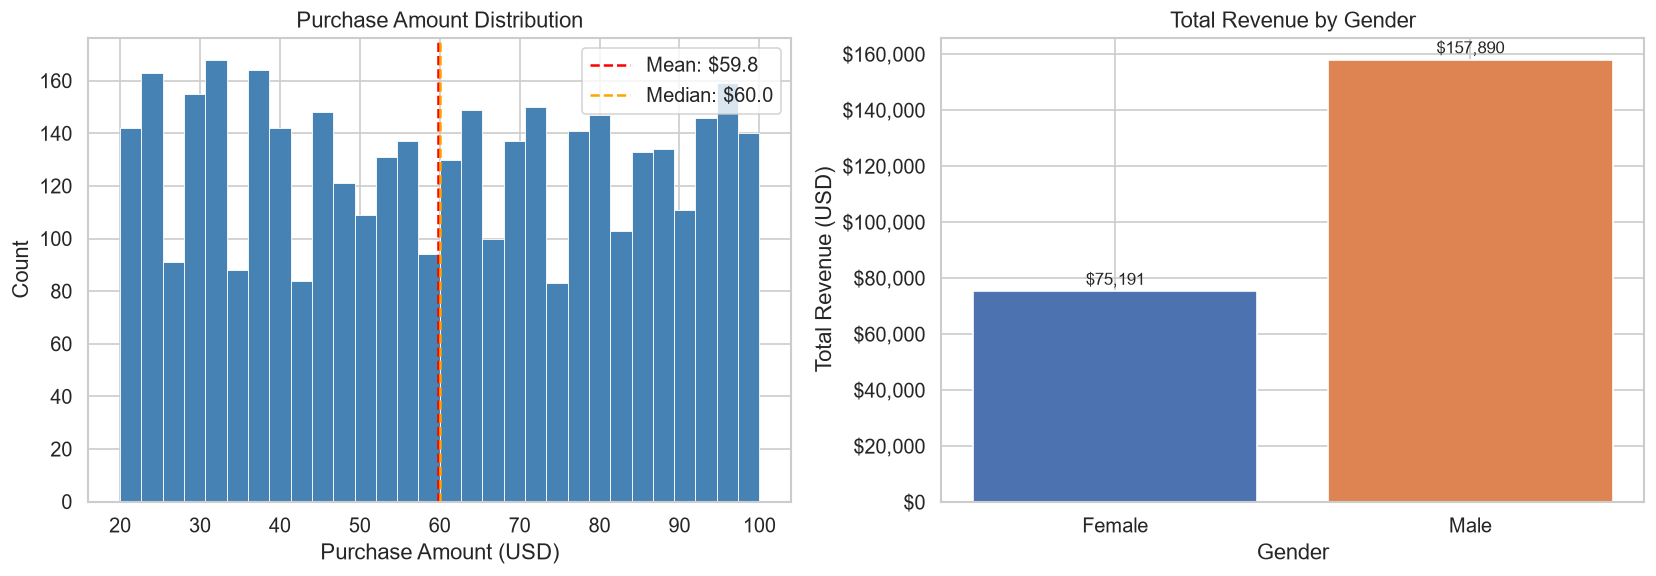

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Purchase amount distribution
axes[0].hist(df['purchase_amount'], bins=30, color='steelblue', edgecolor='white', linewidth=0.5)
axes[0].axvline(df['purchase_amount'].mean(), color='red', linestyle='--', label=f"Mean: ${df['purchase_amount'].mean():.1f}")
axes[0].axvline(df['purchase_amount'].median(), color='orange', linestyle='--', label=f"Median: ${df['purchase_amount'].median():.1f}")
axes[0].set_title('Purchase Amount Distribution')
axes[0].set_xlabel('Purchase Amount (USD)')
axes[0].set_ylabel('Count')
axes[0].legend()

# Revenue by gender
gender_rev = df.groupby('gender')['purchase_amount'].sum().reset_index()
bars = axes[1].bar(gender_rev['gender'], gender_rev['purchase_amount'], color=['#4C72B0', '#DD8452'], edgecolor='white')
for bar in bars:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1000,
                 f"${bar.get_height():,.0f}", ha='center', va='bottom', fontsize=10)
axes[1].set_title('Total Revenue by Gender')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Total Revenue (USD)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

plt.tight_layout()
plt.savefig('../plots/01_purchase_distribution_gender.png', bbox_inches='tight')
plt.show()

### 4.2 Revenue by Category & Season

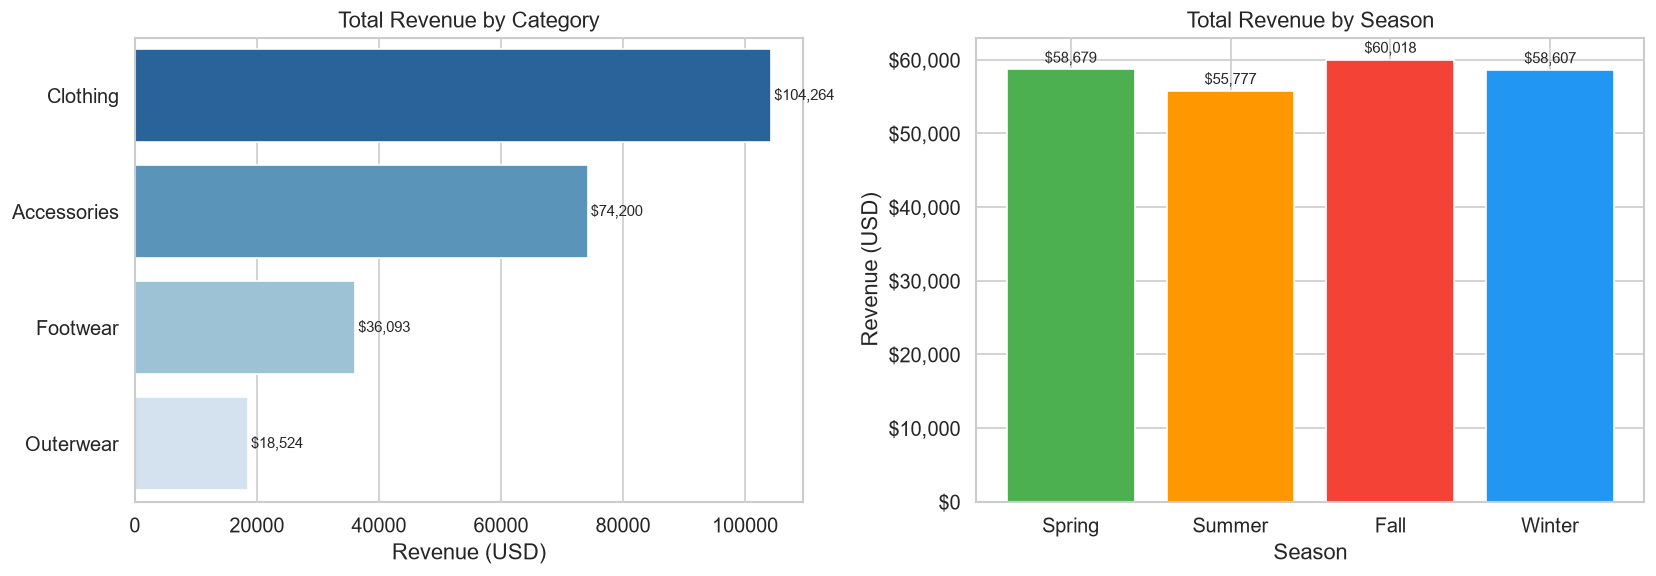

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Revenue by category
cat_rev = df.groupby('category')['purchase_amount'].sum().sort_values(ascending=False)
sns.barplot(x=cat_rev.values, y=cat_rev.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Total Revenue by Category')
axes[0].set_xlabel('Revenue (USD)')
axes[0].set_ylabel('')
for i, v in enumerate(cat_rev.values):
    axes[0].text(v + 500, i, f'${v:,.0f}', va='center', fontsize=9)

# Revenue by season
season_order = ['Spring', 'Summer', 'Fall', 'Winter']
season_rev = df.groupby('season')['purchase_amount'].sum().reindex(season_order)
colors = ['#4CAF50', '#FF9800', '#F44336', '#2196F3']
bars = axes[1].bar(season_rev.index, season_rev.values, color=colors, edgecolor='white')
for bar in bars:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                 f"${bar.get_height():,.0f}", ha='center', va='bottom', fontsize=9)
axes[1].set_title('Total Revenue by Season')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Revenue (USD)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

plt.tight_layout()
plt.savefig('../plots/02_revenue_category_season.png', bbox_inches='tight')
plt.show()

### 4.3 Age Group & Subscription Analysis

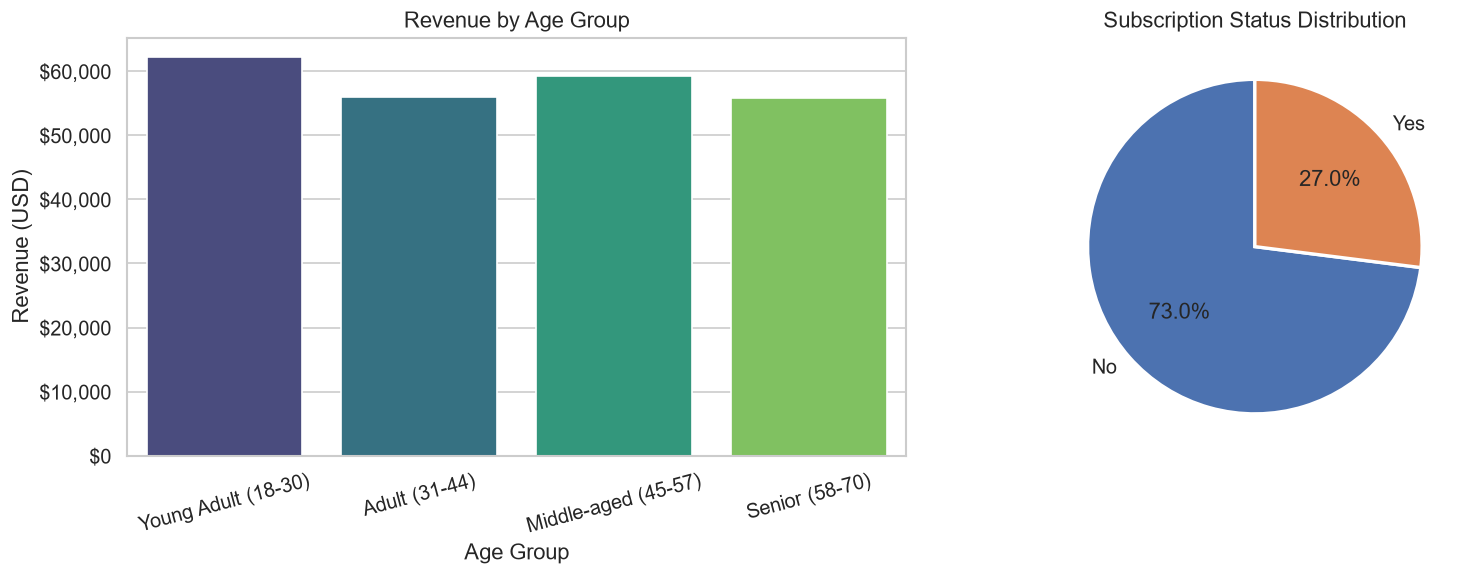

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Revenue by age group
age_rev = df.groupby('age_group', observed=True)['purchase_amount'].sum()
sns.barplot(x=age_rev.index, y=age_rev.values, ax=axes[0], palette='viridis')
axes[0].set_title('Revenue by Age Group')
axes[0].set_xlabel('Age Group')
axes[0].set_ylabel('Revenue (USD)')
axes[0].tick_params(axis='x', rotation=15)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

# Subscription status breakdown
sub_counts = df['subscription_status'].value_counts()
axes[1].pie(sub_counts.values, labels=sub_counts.index,
            autopct='%1.1f%%', startangle=90,
            colors=['#4C72B0', '#DD8452'], wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Subscription Status Distribution')

plt.tight_layout()
plt.savefig('../plots/03_age_group_subscription.png', bbox_inches='tight')
plt.show()

### 4.4 Shipping, Payment & Discount Patterns

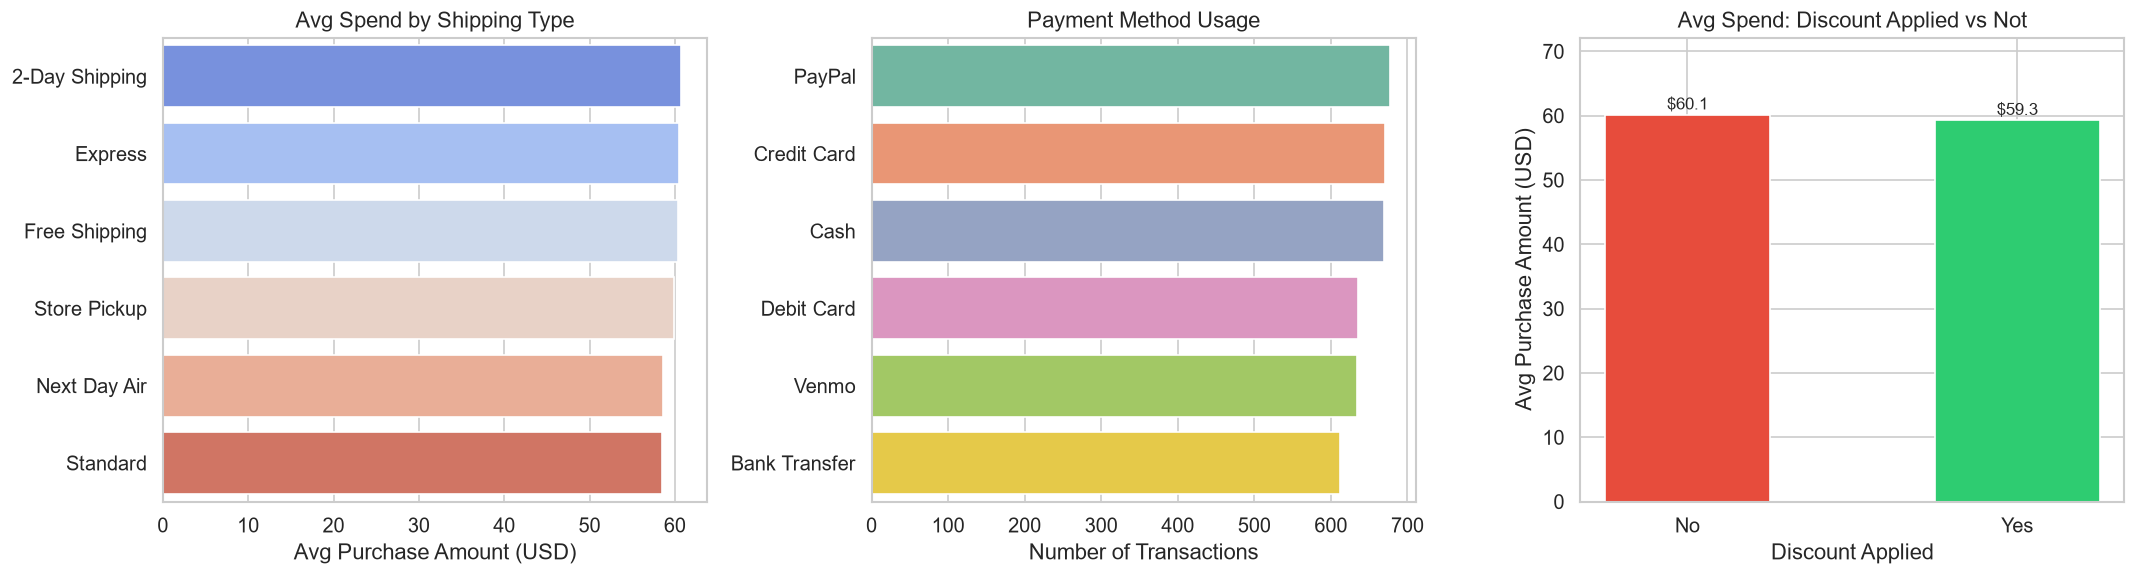

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Avg spend by shipping type
ship_avg = df.groupby('shipping_type')['purchase_amount'].mean().sort_values(ascending=False)
sns.barplot(x=ship_avg.values, y=ship_avg.index, ax=axes[0], palette='coolwarm')
axes[0].set_title('Avg Spend by Shipping Type')
axes[0].set_xlabel('Avg Purchase Amount (USD)')
axes[0].set_ylabel('')

# Payment method distribution
pay_counts = df['payment_method'].value_counts()
sns.barplot(x=pay_counts.values, y=pay_counts.index, ax=axes[1], palette='Set2')
axes[1].set_title('Payment Method Usage')
axes[1].set_xlabel('Number of Transactions')
axes[1].set_ylabel('')

# Discount applied vs avg spend
disc_avg = df.groupby('discount_applied')['purchase_amount'].mean()
bars = axes[2].bar(disc_avg.index, disc_avg.values,
                   color=['#E74C3C', '#2ECC71'], edgecolor='white', width=0.5)
for bar in bars:
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f"${bar.get_height():.1f}", ha='center', va='bottom', fontsize=10)
axes[2].set_title('Avg Spend: Discount Applied vs Not')
axes[2].set_xlabel('Discount Applied')
axes[2].set_ylabel('Avg Purchase Amount (USD)')
axes[2].set_ylim(0, disc_avg.max() * 1.2)

plt.tight_layout()
plt.savefig('../plots/04_shipping_payment_discount.png', bbox_inches='tight')
plt.show()

### 4.5 Top Products & Review Ratings

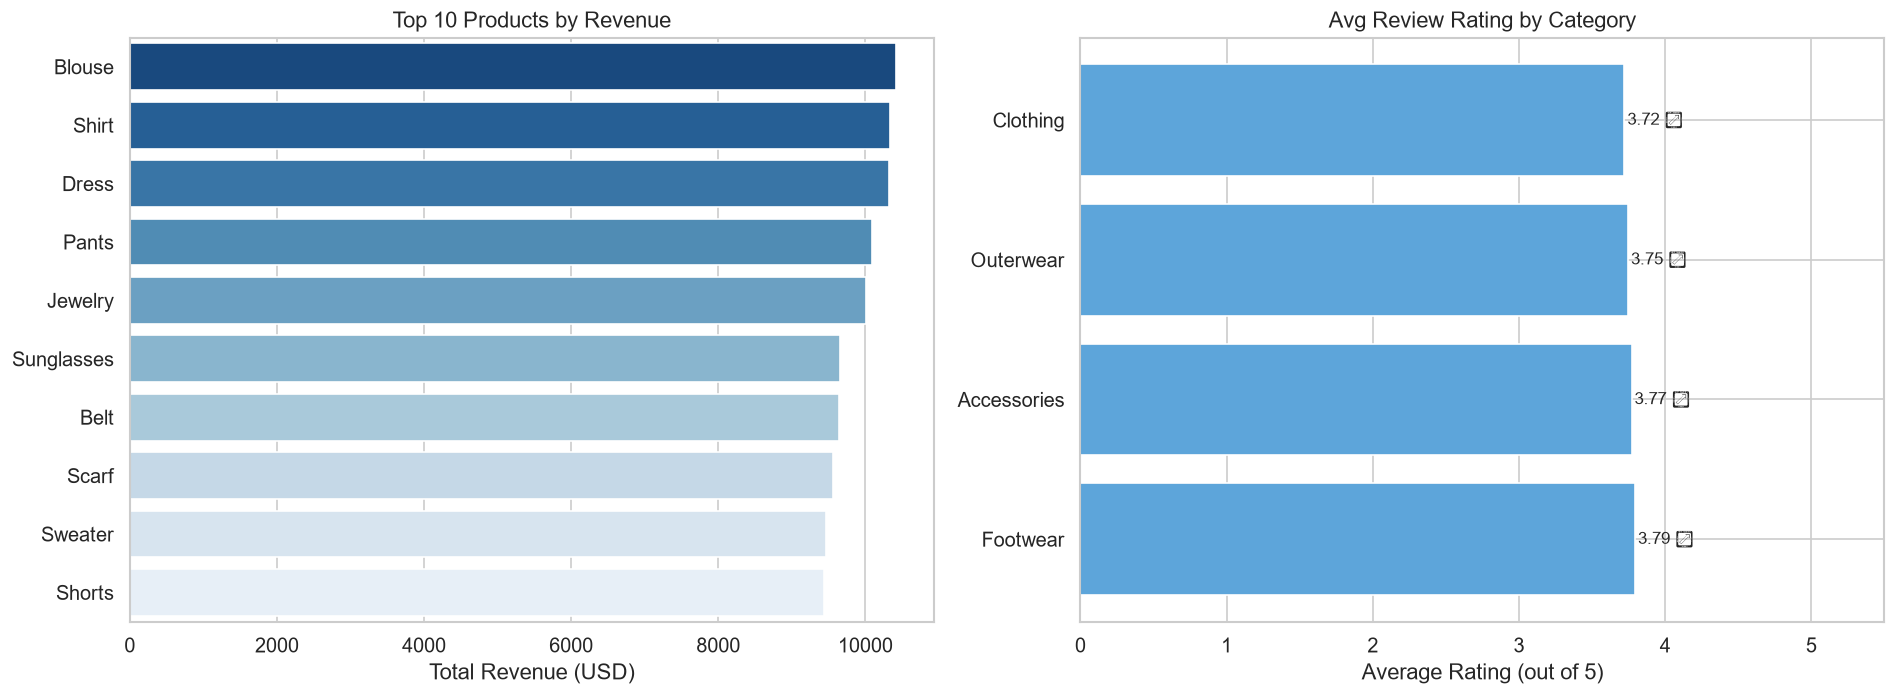

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 items by revenue
top_items = df.groupby('item_purchased')['purchase_amount'].sum().nlargest(10)
sns.barplot(x=top_items.values, y=top_items.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 10 Products by Revenue')
axes[0].set_xlabel('Total Revenue (USD)')
axes[0].set_ylabel('')

# Average review rating by category
rating_cat = df.groupby('category')['review_rating'].mean().sort_values(ascending=False)
bars = axes[1].barh(rating_cat.index, rating_cat.values, color='#5DA5DA', edgecolor='white')
for bar in bars:
    axes[1].text(bar.get_width() + 0.02, bar.get_y() + bar.get_height()/2,
                 f'{bar.get_width():.2f} ⭐', va='center', fontsize=10)
axes[1].set_title('Avg Review Rating by Category')
axes[1].set_xlabel('Average Rating (out of 5)')
axes[1].set_ylabel('')
axes[1].set_xlim(0, 5.5)

plt.tight_layout()
plt.savefig('../plots/05_products_ratings.png', bbox_inches='tight')
plt.show()

### 4.6 Correlation Heatmap

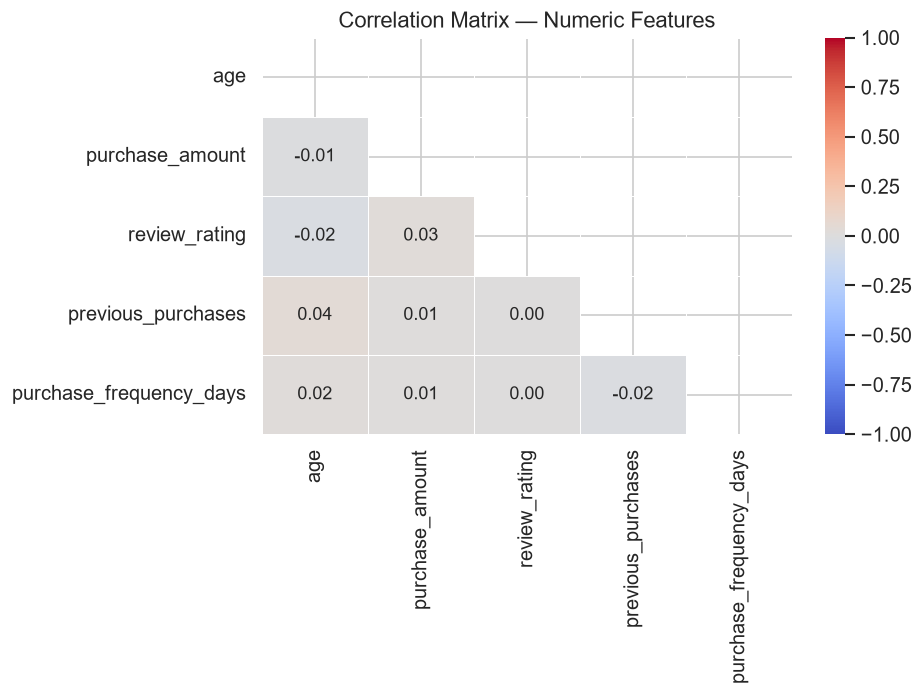

In [20]:
numeric_cols = ['age', 'purchase_amount', 'review_rating', 'previous_purchases', 'purchase_frequency_days']
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            mask=mask, ax=ax, linewidths=0.5, vmin=-1, vmax=1,
            annot_kws={'size': 11})
ax.set_title('Correlation Matrix — Numeric Features')
plt.tight_layout()
plt.savefig('../plots/06_correlation_heatmap.png', bbox_inches='tight')
plt.show()

### 4.7 Loyalty Tier × Subscription Heatmap

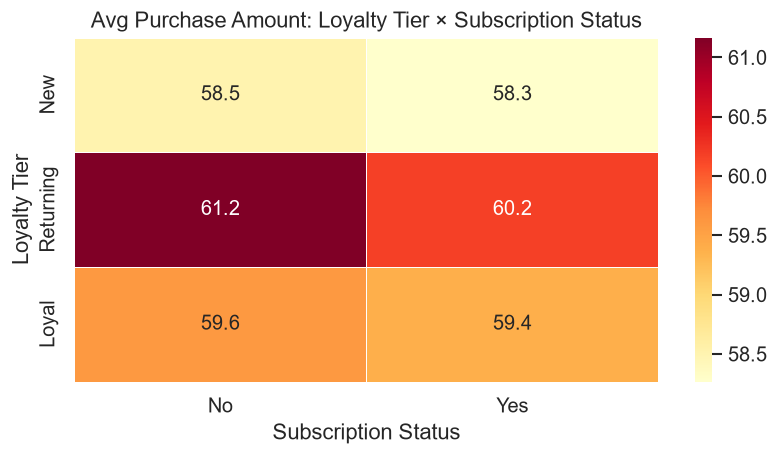

In [21]:
pivot = df.pivot_table(
    index='loyalty_tier',
    columns='subscription_status',
    values='purchase_amount',
    aggfunc='mean'
).reindex(['New', 'Returning', 'Loyal'])

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax,
            linewidths=0.5, annot_kws={'size': 12})
ax.set_title('Avg Purchase Amount: Loyalty Tier × Subscription Status')
ax.set_xlabel('Subscription Status')
ax.set_ylabel('Loyalty Tier')
plt.tight_layout()
plt.savefig('../plots/07_loyalty_subscription_heatmap.png', bbox_inches='tight')
plt.show()

---
## 5. RFM Customer Segmentation

**RFM** (Recency, Frequency, Monetary) is a proven marketing technique to rank and segment customers.

Since this dataset has no actual transaction dates, we use proxy measures:
- **Recency** → `purchase_frequency_days` (lower = more recent shopper)
- **Frequency** → `previous_purchases`
- **Monetary** → `purchase_amount`

In [22]:
# Score each dimension 1-5 (5 = best)
rfm = df[['customer_id', 'purchase_frequency_days', 'previous_purchases', 'purchase_amount']].copy()
rfm.columns = ['customer_id', 'recency_proxy', 'frequency', 'monetary']

# Recency: lower days = higher score (better)
# Use duplicates='drop' to handle repeated bin edges in discrete frequency values
rfm['R'] = pd.qcut(rfm['recency_proxy'], q=5, labels=False, duplicates='drop')
# Invert so lower days = higher score
rfm['R'] = rfm['R'].max() - rfm['R'] + 1
rfm['R'] = rfm['R'].clip(1, 5).astype(int)

# Frequency: higher = better (rank-based to avoid duplicate bin edges)
rfm['F'] = pd.qcut(rfm['frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
# Monetary: higher = better
rfm['M'] = pd.qcut(rfm['monetary'], q=5, labels=[1, 2, 3, 4, 5], duplicates='drop').astype(int)

rfm['RFM_Score'] = rfm['R'] + rfm['F'] + rfm['M']

print('RFM Score Distribution:')
print(rfm['RFM_Score'].describe())

RFM Score Distribution:
count    3900.000000
mean        8.250769
std         2.127794
min         3.000000
25%         7.000000
50%         8.000000
75%        10.000000
max        13.000000
Name: RFM_Score, dtype: float64


In [23]:
def rfm_segment(score):
    if score >= 13:
        return 'Champions'
    elif score >= 10:
        return 'Loyal Customers'
    elif score >= 7:
        return 'Potential Loyalists'
    elif score >= 5:
        return 'At Risk'
    else:
        return 'Lost'

rfm['Segment'] = rfm['RFM_Score'].apply(rfm_segment)

seg_counts = rfm['Segment'].value_counts()
print(seg_counts)

Segment
Potential Loyalists    1958
Loyal Customers        1035
At Risk                 699
Lost                    141
Champions                67
Name: count, dtype: int64


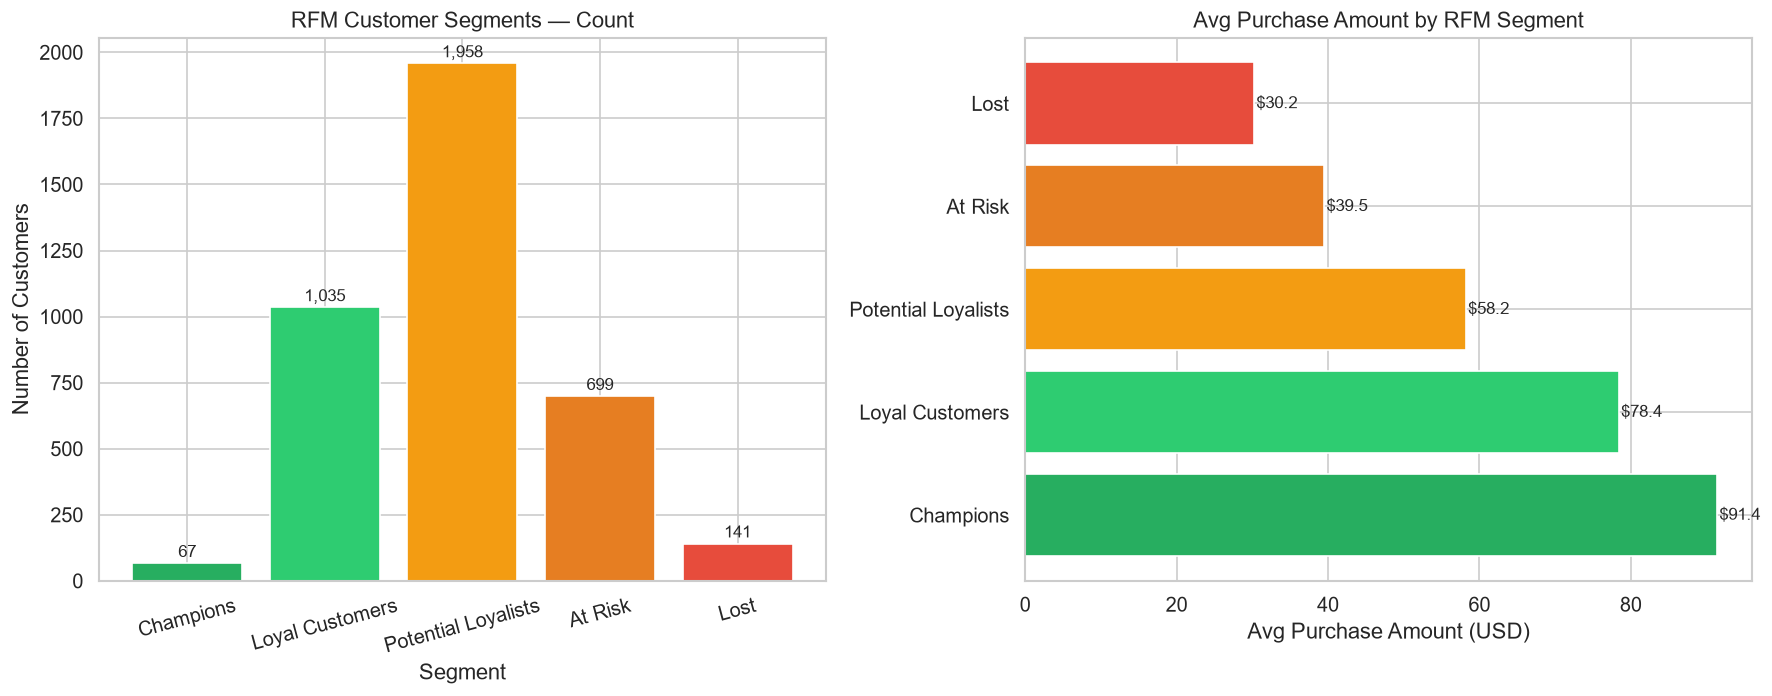

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Segment distribution
seg_order = ['Champions', 'Loyal Customers', 'Potential Loyalists', 'At Risk', 'Lost']
palette = {'Champions': '#27AE60', 'Loyal Customers': '#2ECC71',
           'Potential Loyalists': '#F39C12', 'At Risk': '#E67E22', 'Lost': '#E74C3C'}
seg_data = rfm['Segment'].value_counts().reindex(seg_order)
bars = axes[0].bar(seg_data.index, seg_data.values,
                   color=[palette[s] for s in seg_data.index], edgecolor='white')
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                 f'{bar.get_height():,}', ha='center', va='bottom', fontsize=10)
axes[0].set_title('RFM Customer Segments — Count')
axes[0].set_xlabel('Segment')
axes[0].set_ylabel('Number of Customers')
axes[0].tick_params(axis='x', rotation=15)

# Avg monetary value per segment
avg_monetary = rfm.groupby('Segment')['monetary'].mean().reindex(seg_order)
axes[1].barh(avg_monetary.index, avg_monetary.values,
             color=[palette[s] for s in avg_monetary.index], edgecolor='white')
for i, v in enumerate(avg_monetary.values):
    axes[1].text(v + 0.3, i, f'${v:.1f}', va='center', fontsize=10)
axes[1].set_title('Avg Purchase Amount by RFM Segment')
axes[1].set_xlabel('Avg Purchase Amount (USD)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('../plots/08_rfm_segments.png', bbox_inches='tight')
plt.show()

In [25]:
# Merge RFM segment back into main dataframe
df = df.merge(rfm[['customer_id', 'R', 'F', 'M', 'RFM_Score', 'Segment']],
              on='customer_id', how='left')
df.rename(columns={'Segment': 'rfm_segment', 'R': 'rfm_r', 'F': 'rfm_f', 'M': 'rfm_m',
                   'RFM_Score': 'rfm_score'}, inplace=True)
print(f'Columns after RFM merge: {df.shape[1]}')

Columns after RFM merge: 26


---
## 6. Churn Prediction Model

We define **churn risk** as customers who:
- Purchase infrequently (`purchase_frequency_days >= 90`), AND
- Have a low review rating (`review_rating < 3.5`), AND
- Are not subscribed

We then train a **Random Forest classifier** to predict this churn label from behavioral features.

In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Define churn: infrequent + low-rated + not subscribed
df['is_churn'] = (
    (df['purchase_frequency_days'] >= 90) &
    (df['review_rating'] < 3.5) &
    (df['subscription_status'] == 'No')
).astype(int)

print(f"Churn label distribution:\n{df['is_churn'].value_counts()}")
print(f"\nChurn rate: {df['is_churn'].mean():.1%}")

Churn label distribution:
is_churn
0    3420
1     480
Name: count, dtype: int64

Churn rate: 12.3%


In [27]:
# Select features for the model
feature_cols = [
    'age', 'purchase_amount', 'review_rating', 'previous_purchases',
    'purchase_frequency_days', 'gender', 'category', 'shipping_type',
    'discount_applied', 'payment_method'
]

model_df = df[feature_cols + ['is_churn']].copy()

# Encode categorical columns
cat_cols = ['gender', 'category', 'shipping_type', 'discount_applied', 'payment_method']
le = LabelEncoder()
for col in cat_cols:
    model_df[col] = le.fit_transform(model_df[col])

X = model_df.drop(columns=['is_churn'])
y = model_df['is_churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Train size: {len(X_train)} | Test size: {len(X_test)}')

Train size: 3120 | Test size: 780


In [28]:
# Train Random Forest
rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

print('=' * 50)
print('CHURN PREDICTION — MODEL PERFORMANCE')
print('=' * 50)
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))
print(f'ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}')

CHURN PREDICTION — MODEL PERFORMANCE
              precision    recall  f1-score   support

    No Churn       0.98      0.99      0.99       684
       Churn       0.95      0.88      0.91        96

    accuracy                           0.98       780
   macro avg       0.97      0.93      0.95       780
weighted avg       0.98      0.98      0.98       780

ROC-AUC Score: 0.9969


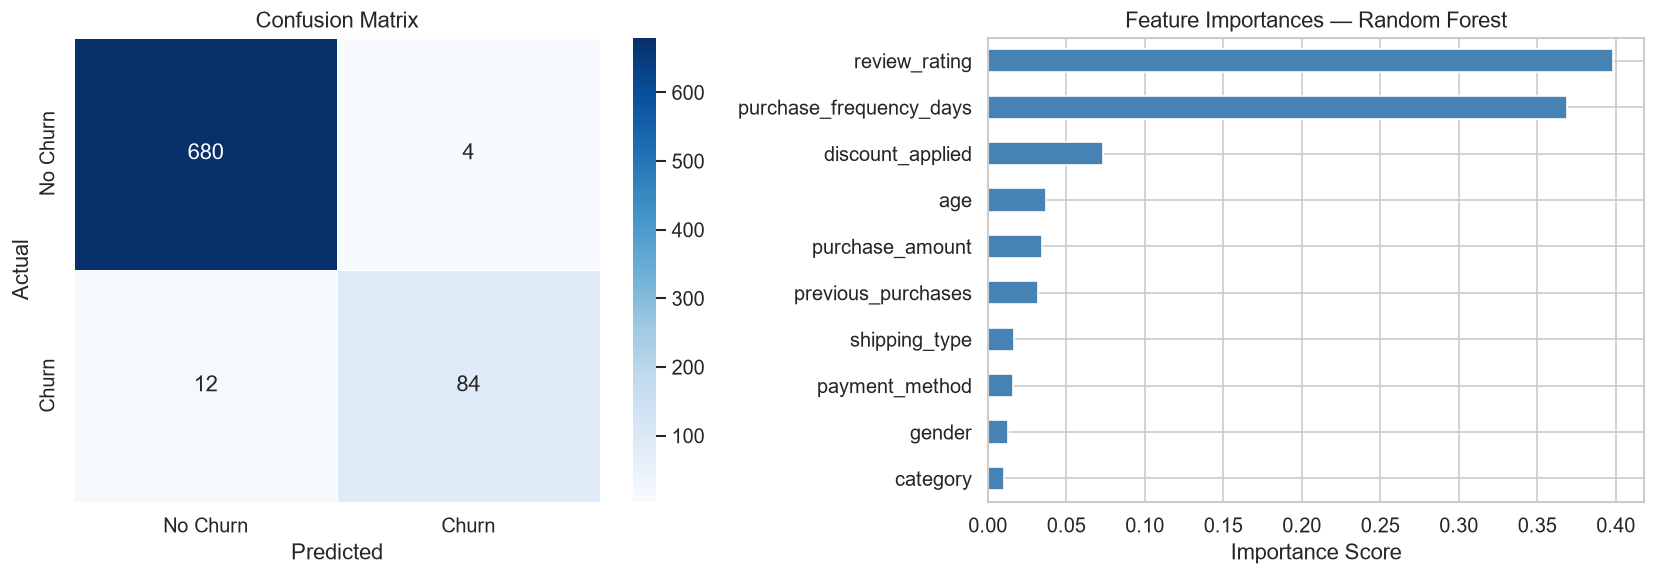

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'],
            linewidths=0.5)
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Feature importance
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=True)
importances.plot(kind='barh', ax=axes[1], color='steelblue', edgecolor='white')
axes[1].set_title('Feature Importances — Random Forest')
axes[1].set_xlabel('Importance Score')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('../plots/09_churn_model.png', bbox_inches='tight')
plt.show()

In [30]:
# Attach churn probability to main dataframe
churn_probs = rf.predict_proba(X)[:, 1]
df['churn_probability'] = churn_probs

# Top 10 highest-risk customers
print('Top 10 at-risk customers:')
df[['customer_id', 'age', 'purchase_amount', 'review_rating',
    'subscription_status', 'churn_probability']].nlargest(10, 'churn_probability')

Top 10 at-risk customers:


,customer_id,age,purchase_amount,review_rating,subscription_status,churn_probability
2788,2789,56,92,3.1,No,0.983793
1926,1927,66,93,3.0,No,0.983340
3762,3763,65,94,2.9,No,0.982118
3151,3152,52,64,3.1,No,0.981031
3591,3592,48,89,3.2,No,0.980795
3778,3779,25,60,2.9,No,0.980462
3583,3584,52,77,2.7,No,0.978328
3143,3144,68,22,2.9,No,0.977986
3042,3043,53,27,2.9,No,0.977561
3416,3417,25,53,3.2,No,0.975802


---
## 7. Load Data into SQL Database

Choose the section matching your database — PostgreSQL, MySQL, or MS SQL Server.

In [31]:
# Save cleaned + enriched dataset as CSV (useful for Power BI or as a SQL backup)
df.to_csv('../data/processed/customer_shopping_behavior_cleaned.csv', index=False)
print(f'Cleaned dataset saved: {df.shape[0]:,} rows × {df.shape[1]} columns')

Cleaned dataset saved: 3,900 rows × 28 columns


### 7a. PostgreSQL

In [32]:
# from sqlalchemy import create_engine
#
# Replace with your credentials
# PG_USER     = "postgres"
# PG_PASSWORD = "your_password"
# PG_HOST     = "localhost"
# PG_PORT     = "5432"
# PG_DB       = "customer_behavior"
#
# engine = create_engine(
#     f"postgresql+psycopg2://{PG_USER}:{PG_PASSWORD}@{PG_HOST}:{PG_PORT}/{PG_DB}"
# )
# df.to_sql("customer", engine, if_exists="replace", index=False)
# print("Data loaded into PostgreSQL ✅")

### 7b. MySQL

In [33]:
# from sqlalchemy import create_engine
#
# MYSQL_USER     = "root"
# MYSQL_PASSWORD = "your_password"
# MYSQL_HOST     = "localhost"
# MYSQL_PORT     = "3306"
# MYSQL_DB       = "customer_behavior"
#
# engine = create_engine(
#     f"mysql+pymysql://{MYSQL_USER}:{MYSQL_PASSWORD}@{MYSQL_HOST}:{MYSQL_PORT}/{MYSQL_DB}"
# )
# df.to_sql("customer", engine, if_exists="replace", index=False)
# print("Data loaded into MySQL ✅")

### 7c. MS SQL Server

In [34]:
# from sqlalchemy import create_engine
# from urllib.parse import quote_plus
#
# MSSQL_USER     = "sa"
# MSSQL_PASSWORD = "your_password"
# MSSQL_HOST     = "localhost"
# MSSQL_PORT     = "1433"
# MSSQL_DB       = "customer_behavior"
# DRIVER = quote_plus("ODBC Driver 17 for SQL Server")
#
# engine = create_engine(
#     f"mssql+pyodbc://{MSSQL_USER}:{MSSQL_PASSWORD}@{MSSQL_HOST},{MSSQL_PORT}/{MSSQL_DB}?driver={DRIVER}"
# )
# df.to_sql("customer", engine, if_exists="replace", index=False)
# print("Data loaded into SQL Server ✅")